# Livrable final — Optimisation de tournées de livraison

**CVRPTW : capacités et fenêtres horaires strictes**  
**Projet CESI — Algorithmique et optimisation**

## Introduction

La préparation de tournées consiste à décider quel camion dessert chaque client
et dans quel ordre. Une distance courte n'est utile que si les livraisons sont
possibles : il faut respecter la capacité des camions, les horaires des clients
et la fermeture du dépôt. Nous étudions ce problème dans le contexte CesiCDP et
de l'appel à projets de l'ADEME. Réduire les déplacements répond à un enjeu de
mobilité ; nos instances abstraites ne permettent pas de chiffrer un gain réel
d'émissions ou de consommation.

Notre étude suit une chaîne complète : formalisation, construction de solutions,
recherche d'améliorations, vérification indépendante et comparaison aux références.
Nous développons une **ALNS**, qui alterne retraits et réinsertions de clients.
Le recuit simulé permet d'explorer certaines dégradations ; une archive conserve
la meilleure solution réalisable. Les fonctions numériques sont compilées avec
Numba, mais les tournées sont produites par notre propre méthode.

Le critère des benchmarks est la **distance totale**. Le nombre de véhicules
reste borné par le fichier ; employer moins de véhicules n'a pas de priorité
sur la distance. L'objectif de durée complète du projet est étudié séparément.

In [1]:
from pathlib import Path
import sys,json,inspect
ROOT=Path.cwd()
sys.path.insert(0,str(ROOT))
from IPython.display import display,Image
from algo.solver import solve,Settings,warmup
from algo.data import load
from algo.verify import verify
from algo import kernels
FIG=ROOT/'results/report/figures'
progress=json.loads((ROOT/'results/final/progress.json').read_text())
assert progress['complete'] and progress['completed']==1000
focus=json.loads((ROOT/'results/focused/progress.json').read_text())
assert focus['complete'] and focus['completed']==80
print('Étude principale : 80 nouveaux essais sur 28 instances. Extension : 1 000 trajectoires sur 356 instances.')

Étude principale : 80 nouveaux essais sur 28 instances. Extension : 1 000 trajectoires sur 356 instances.


## 1. Problème et modélisation

### 1.1. Données et périmètre

Nous traitons un dépôt unique, une flotte homogène et des demandes indivisibles.
Chaque client est servi une seule fois. Les trajets sont fixes et symétriques.
Le trafic variant selon l'heure n'est pas modélisé : cela demanderait des données
et un calcul d'horaires dépendant de l'instant de départ. Les expériences
présentées ne constituent pas une validation de cette extension.

| Symbole | Donnée |
|---|---|
| $C=\{1,\ldots,n\}$ | Clients ; le dépôt est noté $0$ |
| $q_i$, $s_i$ | Demande et durée de service |
| $[e_i,l_i]$ | Ouverture et fermeture du début de service |
| $Q$, $K$, $H$ | Capacité, flotte maximale et fermeture du dépôt |
| $d_{ij}$, $c_{ij}$ | Distance et temps de trajet |

Une solution est une liste de tournées, par exemple `[[1,3],[2,4]]`. Les dépôts
de départ et de retour sont implicites dans le code. Les positions d'une liste
définissent l'ordre de passage, pas les horaires : ceux-ci sont recalculés.

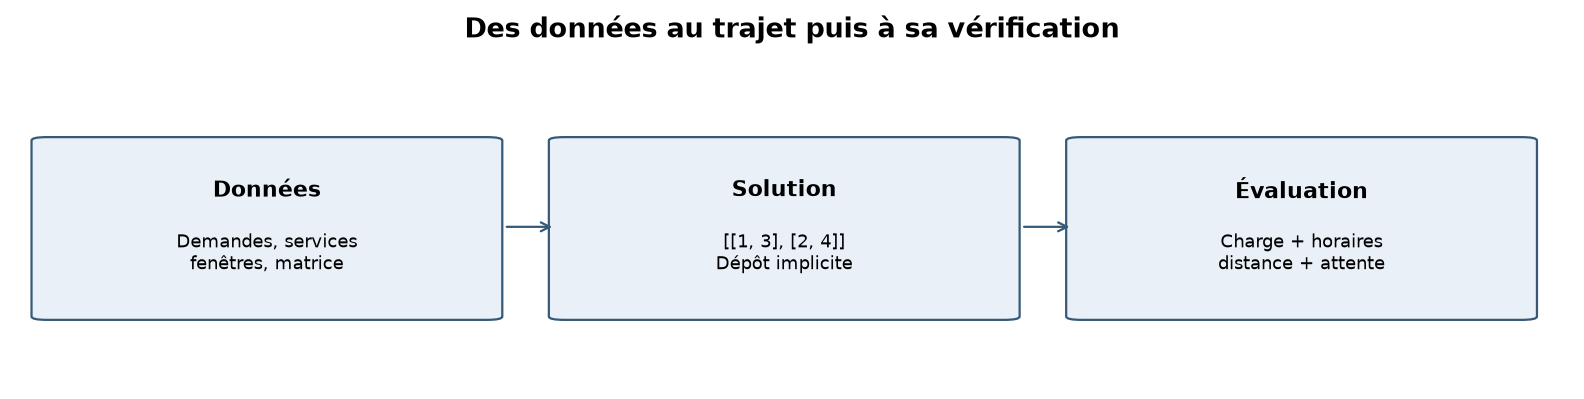

In [2]:
display(Image(filename=str(FIG/'representation.png')))

Pour rendre cette représentation concrète, l'exemple suivant comporte deux
clients, une capacité de six unités et une fermeture du dépôt à 60. Il s'agit
d'un cas pédagogique, distinct des benchmarks. Nous affichons ses demandes,
ses fenêtres, sa matrice et les horaires calculés par le vérificateur.

In [3]:
import numpy as np,pandas as pd
from algo.model import Instance
toy=Instance('exemple',np.array([[0,0],[8,0],[4,3]]),np.array([0,2,3]),
    np.array([0,5,4]),np.array([0,15,0]),np.array([60,25,40]),
    np.array([[0,8,5],[8,0,5],[5,5,0]]),6.,2,60.)
display(pd.DataFrame({'Client':[1,2],'Demande':[2,3],'Service':[5,4],
    'Ouverture':[15,0],'Fermeture':[25,40]}))
display(pd.DataFrame(toy.distance,index=['Dépôt','Client 1','Client 2'],columns=['Dépôt','Client 1','Client 2']).rename_axis('Depuis / vers').reset_index())
examples=[]
for route in [[1,2],[2,1]]:
    v=verify([route],toy)
    assert v['valid']
    examples.append({'Ordre':str(route),'Charge':sum(toy.demand[route]),'Distance':v['distance'],
        'Trajet':v['travel'],'Attente':v['waiting'],'Service':9,'Durée':v['duration']})
display(pd.DataFrame(examples))

,Client,Demande,Service,Ouverture,Fermeture
0,1,2,5,15,25
1,2,3,4,0,40


,Depuis / vers,Dépôt,Client 1,Client 2
0,Dépôt,0.0,8.0,5.0
1,Client 1,8.0,0.0,5.0
2,Client 2,5.0,5.0,0.0


,Ordre,Charge,Distance,Trajet,Attente,Service,Durée
0,"[1, 2]",5.0,18.0,18.0,7.0,9,34.0
1,"[2, 1]",5.0,18.0,18.0,1.0,9,28.0


Les deux ordres de visite parcourent la même distance, mais n'attendent pas
autant. Ce petit cas montre pourquoi nous séparons distance et durée, avant
d'aborder les résultats sur plusieurs centaines de clients.

Les références utilisées proviennent du répertoire VRPTW de **PyVRP/Instances**,
à une révision figée. VRPLIB lit les fichiers et ne les résout pas. Nous suivons
la convention DIMACS publiée avec ces références : chaque trajet euclidien est
tronqué à une décimale. Les calculs utilisent $\lfloor10d_{ij}\rfloor$ en unités
entières ; fenêtres et services sont également exprimés en dixièmes. La division
par dix intervient pour présenter les coûts. Nous ne tronquons pas seulement la
distance totale après la recherche.

Cette convention définit le benchmark : elle n'est pas un réglage modifié après
observation des résultats. Les références en double précision ou privilégiant
d'abord la flotte ne sont pas mélangées à ces mesures.


### 1.2. Calcul des horaires

Les véhicules partent à l'ouverture du dépôt, fixée à zéro. Si le client $j$
succède à $i$, son arrivée et son début de service sont :

$$a_j=t_i+s_i+c_{ij},\qquad t_j=\max(a_j,e_j).$$

L'attente est $t_j-a_j$. Un service doit **commencer** avant $l_j$ ; sa fin
peut dépasser cette borne. La charge de chaque tournée ne dépasse pas $Q$ et
le dernier trajet doit ramener le véhicule au dépôt avant $H$.

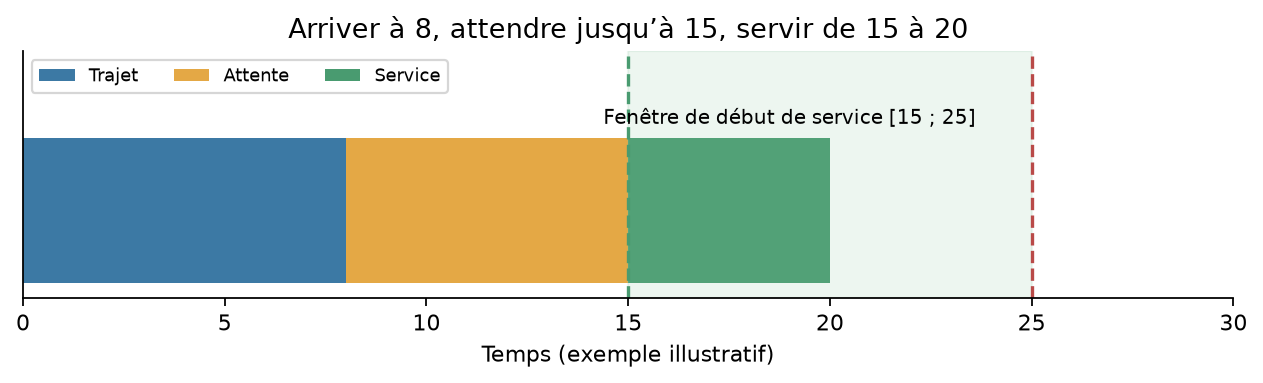

In [4]:
display(Image(filename=str(FIG/'schedule.png')))

### 1.3. Deux objectifs à distinguer

Pour comparer les benchmarks DIMACS, nous minimisons

$$F_{\mathrm{distance}}=\sum_{k=1}^{K}\sum_{(i,j)}d_{ij}x_{ij}^{k}.$$

Nous n'ajoutons aucun coût fixe d'utilisation d'un camion. Si deux solutions
respectent la flotte maximale, leur classement dépend de leur distance.
Une solution à davantage de véhicules peut donc être meilleure selon ce critère.

Pour l'objectif métier, nous minimisons la somme des durées entre départ et
retour, soit $F_{\mathrm{durée}}=\sum_kR_k$. Avec un départ commun à zéro,
cette durée inclut trajets, services et attentes. Une amélioration de distance
ne garantit pas une amélioration identique de durée ; le gap d'une référence
en distance ne mesure pas cet autre objectif.

### 1.4. Formulation PLNE complète

Nous dupliquons le dépôt en un départ $o$ et un retour $r$. Les arcs autorisés
sont $(o,i)$, $(i,r)$ et $(i,j)$ entre clients distincts. Pour chaque véhicule
$k$, la variable binaire $x_{ij}^{k}$ vaut un si cet arc est parcouru. Nous
notons $y_i^k=\sum_jx_{ij}^{k}$ l'affectation et $u_k=\sum_jx_{oj}^{k}$
l'utilisation du véhicule. $t_i$ et $R_k$ sont les débuts de service et retours.
Les sommes suivantes portent uniquement sur les arcs autorisés.

**Visiter chaque client et conserver son véhicule :**

$$\sum_k\sum_jx_{ij}^{k}=1\quad(i\in C),\qquad
\sum_jx_{ji}^{k}=\sum_jx_{ij}^{k}\quad(i\in C,\ k=1,\ldots,K).$$

**Assurer le départ, le retour et la capacité :**

$$\sum_jx_{oj}^{k}=\sum_ix_{ir}^{k}=u_k\leq1,\qquad
\sum_{i\in C}q_iy_i^k\leq Q\quad(k=1,\ldots,K).$$

**Propager les horaires et respecter les fenêtres :**

$$e_i\leq t_i\leq l_i\quad(i\in C),$$
$$t_j\geq c_{oj}-M(1-x_{oj}^{k})\quad(j\in C,\ k=1,\ldots,K),$$
$$t_j\geq t_i+s_i+c_{ij}-M(1-x_{ij}^{k})
\quad(i\ne j\in C,\ k=1,\ldots,K).$$

**Fixer le retour et annuler celui d'un véhicule inutilisé :**

$$R_k\geq t_i+s_i+c_{ir}-M(1-x_{ir}^{k}),$$
$$R_k\leq t_i+s_i+c_{ir}+M(1-x_{ir}^{k})
\quad(i\in C,\ k=1,\ldots,K),\qquad0\leq R_k\leq Hu_k.$$

La borne $M=H+s_{\max}+c_{\max}$ désactive les implications inutilisées.
Le modèle suppose les fenêtres comprises dans l'horizon $H$, comme nos données.
Une borne plus précise par arc améliorerait une résolution exacte.

**Éliminer les cycles déconnectés du dépôt :** des temps tronqués peuvent être
nuls. Nous ne nous appuyons donc pas uniquement sur la chronologie pour éliminer
les sous-tournées. Un flot artificiel continu $z_{ij}^k$ satisfait :

$$0\leq z_{ij}^{k}\leq nx_{ij}^{k},\qquad z_{ir}^{k}=0,$$
$$\sum_jz_{ji}^{k}-\sum_jz_{ij}^{k}=y_i^k
\quad(i\in C,\ k=1,\ldots,K),$$
$$\sum_jz_{oj}^{k}=\sum_iy_i^k\quad(k=1,\ldots,K).$$

Chaque client consomme une unité reçue depuis le dépôt. Un cycle isolé ne peut
alimenter cette consommation. Nous minimisons $F_{\mathrm{distance}}$ pour le
benchmark, ou $F_{\mathrm{durée}}$ pour l'étude métier. Le PLNE formalise le
problème ; il n'est pas le moteur des grandes campagnes.

### 1.5. Difficulté théorique

La décision demande s'il existe des tournées réalisables de coût au plus $B$.
Une liste de clients ordonnés constitue un certificat vérifiable en temps
polynomial : couverture, charges, horaires et coût se recalculent directement.
Les données rationnelles sont supposées encodées en binaire.

Un TSP symétrique à coûts positifs se transforme en notre problème en prenant
un véhicule, des demandes unitaires, une capacité $n$, des services nuls et des
fenêtres $[0,H]$ avec $H=(n+1)c_{\max}$. Le seuil $B$ est conservé. Le tour
TSP existe sous ce seuil exactement lorsque la tournée correspondante existe.
La transformation est polynomiale : la décision générale est NP-complète et
l'optimisation NP-difficile. Cela justifie une recherche approchée, sans exclure
la résolution exacte de petits cas.

Un oracle exhaustif énumère les petites tournées réalisables puis combine
leurs sous-ensembles par programmation dynamique. Il est limité à huit clients
et sert à contrôler des exemples ; il ne remplace pas l'ALNS sur les références.
Le contrôle suivant retrouve les optimums de notre exemple pédagogique dans
les deux objectifs. Il ne résout pas directement le PLNE présenté plus haut.

In [5]:
from controle.exact import exact
from algo.model import Objective
oracle_distance=exact(toy,Objective.DISTANCE)
oracle_duration=exact(toy,Objective.DURATION)
assert oracle_distance['status']==oracle_duration['status']=='optimal'
assert oracle_distance['score']==18 and oracle_duration['score']==28
print('Optimum exact de l’exemple : distance',oracle_distance['score'],'; durée',oracle_duration['score'])

Optimum exact de l’exemple : distance 18.0 ; durée 28.0


## 2. Choix de la méthode

Une modification d'affectation change simultanément les charges et les horaires.
Un échange isolé peut échouer alors qu'une réorganisation de plusieurs clients
réussit. Nous choisissons donc une **recherche à grands voisinages adaptative**.

L'ALNS utilise une solution courante et une meilleure solution conservée. Elle
n'entretient pas une population génétique. Les opérateurs de retrait reçoivent
des poids qui évoluent avec leurs résultats ; le recuit décide si une candidate
réalisable peut remplacer la solution courante. Ces mécanismes ont des rôles
différents : choisir où chercher et accepter ou non ce qui a été trouvé.

Nous ne prétendons pas démontrer sa supériorité sur toutes les métaheuristiques.
La recherche taboue serait également pertinente. Notre choix privilégie une
représentation explicite, des insertions contrôlées et des expériences reproductibles.

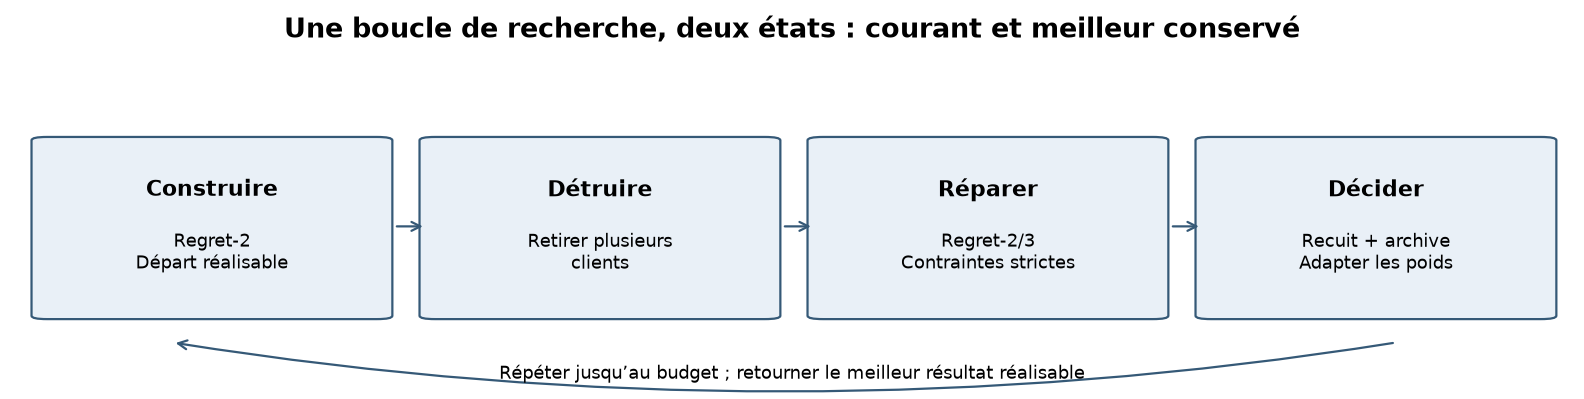

In [6]:
display(Image(filename=str(FIG/'algorithm.png')))

## 3. Algorithme et code

### 3.1. Construire et réparer

Nous essayons des constructions regret-2, avec une première version sans bruit
puis des coûts légèrement perturbés. La meilleure construction réalisable est
retenue. Le nombre maximal est douze, mais le budget de construction limite les
tentatives suivantes. Une première tentative atomique peut dépasser cette réserve.
Un échec signifie que la méthode n'a pas trouvé de départ, pas que le problème
est mathématiquement impossible.

Pour chaque client non affecté, nous calculons les meilleures insertions dans
des tournées distinctes. Le regret-2 est la différence entre les deux meilleures
possibilités. Des surcoûts de 4 et 20 donnent un regret de 16 ; des surcoûts de
5 et 7 donnent un regret de 2. Le premier client est plus urgent à placer.
Les clients disposant de trop peu d'alternatives sont prioritaires.

Les horaires au plus tôt et au plus tard permettent de tester une insertion
sans propager toute la tournée pour chaque position. La capacité et le retour
au dépôt restent contrôlés. Une suppression pouvant rendre une route partielle
irréalisable sur une matrice tronquée, cette route est démontée avant réparation.

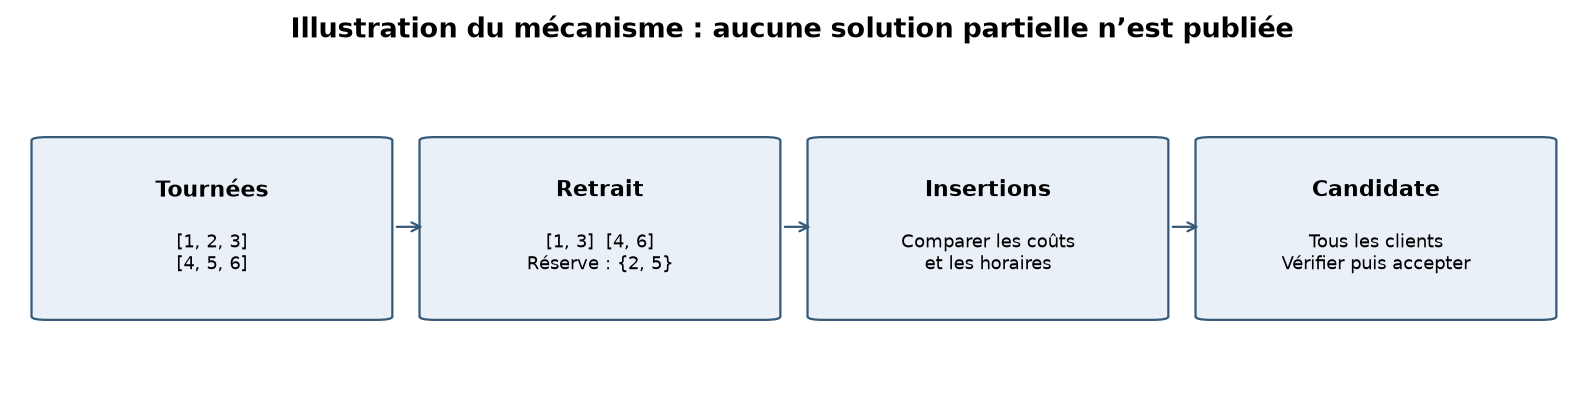

In [7]:
display(Image(filename=str(FIG/'repair.png')))

### 3.2. Explorer des voisinages

| Retrait | Intention |
|---|---|
| Aléatoire | Diversifier les affectations |
| Géographique et apparenté | Réorganiser des clients liés spatialement ou temporellement |
| Contribution coûteuse | Supprimer des détours potentiels |
| Fenêtres étroites | Reconsidérer des clients contraignants |
| Tournée complète occasionnelle | Ouvrir une réaffectation plus profonde |

Les retraits ordinaires sont plafonnés à quarante clients. Une tournée entière
peut dépasser ce plafond. La réparation utilise regret-2 ou regret-3. Une
réparation incomplète est rejetée et ne devient jamais une solution publiée.

La recherche locale examine relocate, swap, 2-opt et 2-opt*. Chaque mouvement
retenu doit diminuer la distance et conserver la faisabilité des routes.
Supprimer un véhicule n'autorise aucune augmentation du coût.

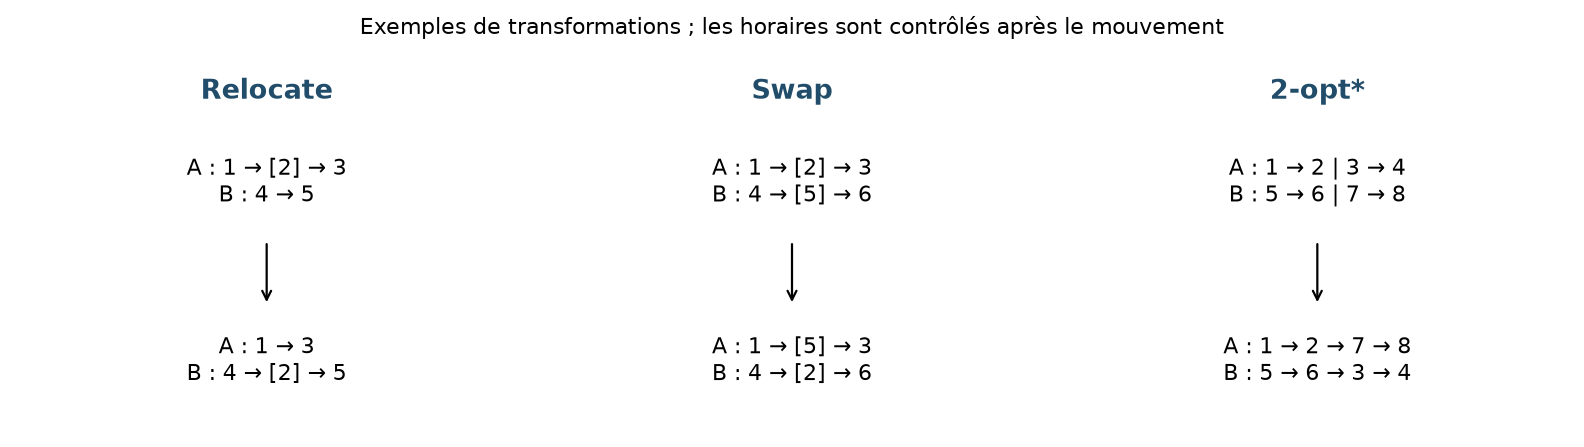

In [8]:
display(Image(filename=str(FIG/'moves.png')))

### 3.3. Acceptation et adaptation

Pour une candidate de distance $D'$ et la solution courante de distance $D$,
$\Delta=D'-D$. Une amélioration est acceptée ; une dégradation est acceptée
avec la probabilité $\exp(-\Delta/T)$. Le meilleur résultat reste conservé
séparément, même si la solution courante se dégrade.

Nous utilisons $T_0=0{,}02D_{\mathrm{construction}}$ et un refroidissement
géométrique vers $0{,}005T_0$ selon le budget consommé. Les poids suivent
$w\leftarrow0{,}9w+0{,}1r$ : récompense 5 pour un nouveau meilleur résultat,
1 pour une amélioration acceptée, 0,2 pour une autre acceptation et 0,05 sinon.
Après 200 itérations sans nouveau meilleur, la recherche repart de l'archive.
Ces valeurs sont des réglages empiriques ; l'étude de sensibilité les examine
sans modifier rétroactivement le protocole principal.

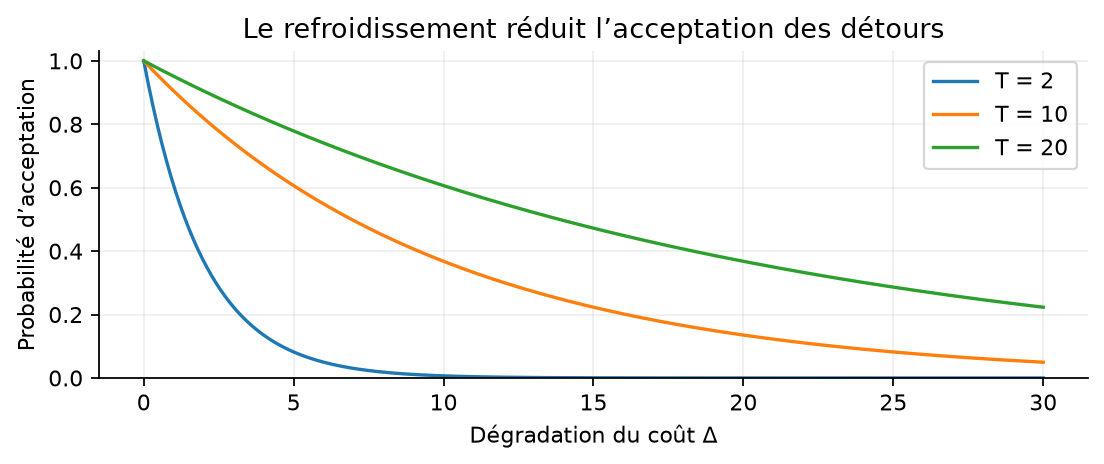

In [9]:
display(Image(filename=str(FIG/'acceptance.png')))

### 3.4. Intensifier les grands cas

Une expérience exploratoire sur six cas difficiles a comparé cinq secondes
de continuation globale à cinq secondes de recherche par groupes de tournées,
depuis les mêmes départs. La seconde stratégie a gagné cinq comparaisons et
perdu une. Ces cas ont été sélectionnés après observation ; ce pilote ne
constitue donc pas une validation indépendante.

Nous appliquons ensuite une règle identique à toutes les trajectoires d'au
moins 400 clients : cinq secondes supplémentaires sur des groupes géographiquement
proches, visant environ 120 clients et douze tournées au maximum. Les tournées
sont conservées entières, donc une tournée longue peut dépasser la cible de
120 clients. Chaque sous-problème reçoit jusqu'à 0,2 seconde et conserve les
temps, distances, services, demandes et fenêtres d'origine. Jusqu'à trois
véhicules supplémentaires peuvent être ouverts dans un groupe, sous réserve
de la limite globale ; aucune pénalité de flotte n'est ajoutée.

Une candidate ne remplace le résultat que si sa distance diminue et que la
solution globale est réalisable. Les groupes facilitent des échanges locaux,
mais leurs frontières peuvent aussi masquer une amélioration plus globale.
Le moteur ne lit aucune BKS pour guider cette phase.

Les cas de 1 000 clients reçoivent une seconde passe de cinq secondes selon
la même règle de taille. Cet effort supplémentaire a été décidé après le bilan
initial complet, dont le gap moyen à cette taille était de 10,003 %. Les deux
passes sont conservées séparément ; l'étude reste une optimisation sur un lot
connu, pas une validation aveugle. Le budget cumulé atteint 25 secondes pour
ces plus grands cas.
La première passe seule avait ramené leur moyenne de 10,003 % à 6,892 % sur
les mêmes 167 trajectoires, en passant de quinze à vingt secondes nominales.
Le tableau final évalue ensuite la seconde passe ; le coût du calcul
supplémentaire reste explicite.

### 3.5. Arrêt, coût de calcul et organisation

L'arrêt principal dépend du temps de recherche, construction incluse. Les
opérations internes sont atomiques : un mouvement commencé peut finir après
l'échéance. Les temps réels sont donc publiés avec le budget nominal.

Avec $q$ clients retirés, la réparation évalue jusqu'à $q$ clients sur les
positions disponibles, puis actualise les coûts après insertion. Une borne
prudente est $O(q^2(n+K))$, en plus des copies $O(Kn)$ et des tris de retrait.
La construction complète peut être cubique. Les matrices demandent une mémoire
$O(n^2)$ ; Numba accélère les boucles sans changer cet ordre de croissance.
La recherche locale ajoute des vérifications de routes, linéaires dans leur
longueur ; son nombre de mouvements est plafonné. Les tableaux de tournées
occupent également $O(Kn)$ emplacements.

| Fichier | Responsabilité |
|---|---|
| `algo/data.py` | Lecture des données et convention DIMACS |
| `algo/model.py` | Données communes et invariants |
| `algo/kernels.py` | Insertions, retraits et mouvements compilés |
| `algo/solver.py` | ALNS, recuit, adaptation et archive |
| `algo/verify.py` | Vérification indépendante des solutions |
| `ameliorations/decomposition.py` | Intensification par groupes de tournées |
| `scripts/run_campaign.py` | Protocole figé, exécutions et reprise |
| `metier/` | Étude séparée de l'objectif durée |

In [10]:
print(inspect.getsource(kernels.best_insert.py_func))

@njit(cache=True)
def best_insert(routes,lens,r,c,travel,distance,demand,service,early,late,capacity,horizon,depart,latest,load,noise):
    if load+demand[c]>capacity+TOL:return 1e100,-1
    L=lens[r];best=1e100;position=-1;true_delta=1e100
    for p in range(L+1):
        prev=routes[r,p-1] if p else 0
        nxt=routes[r,p] if p<L else 0
        begin=max(depart[r,p]+travel[prev,c],early[c])
        if begin>late[c]+TOL:continue
        if begin+service[c]+travel[c,nxt]>latest[r,p]+TOL:continue
        delta=distance[prev,c]+distance[c,nxt]-distance[prev,nxt]
        ranking=delta*(1+noise*(2*np.random.random()-1)) if noise>0 else delta
        if ranking<best:
            best=ranking;position=p;true_delta=delta
    return true_delta,position



## 4. Données de référence et protocole

Les mesures sont issues de Windows-10-10.0.19045-SP0, sur AMD Ryzen 5 3600 6-Core Processor, avec 6 cœurs physiques et environ 15.9 Gio de mémoire. Python 3.12.8, NumPy 2.4.1, Numba 0.68.1 et VRPLIB 2.2.0 sont utilisés. Les versions et le placement des processus figurent dans les fichiers d'environnement et de protocole.

L'étude principale suit **28 problèmes et 80 nouvelles résolutions depuis zéro**.
Nous retenons les quatre premiers identifiants de chacune des six familles
Solomon, soit 24 instances à 100 clients. Chacune reçoit les graines 11, 22 et
33, donc 72 essais. Les cas C1_2_1 et R1_2_1 à 200 clients reçoivent la graine
11 ; C1_10_1 et R1_10_1 à 1 000 clients reçoivent trois graines, soit six essais.
La liste a été fixée avant ces nouvelles exécutions. Ces problèmes avaient
déjà été observés : nous ne présentons pas ce lot comme un test aveugle.

Une extension antérieure couvre les **356 problèmes publics et 1 000
trajectoires**. Elle est analysée séparément dans la partie grandes instances,
et conservée intégralement. Les deux lots ne sont pas additionnés pour annoncer
384 problèmes différents : leurs instances se recouvrent.

Les budgets du lot principal sont de cinq secondes à 100 clients, six à 200
et vingt-cinq à 1 000, dont deux passes finales de cinq secondes. L'extension
ajoute les tailles 400, 600 et 800, avec des budgets cumulés de 13, 15 et
17 secondes. Ces budgets adaptés à la taille n'isolent pas son effet à temps
identique. Les études de paramètres et de durée restent des lots séparés.

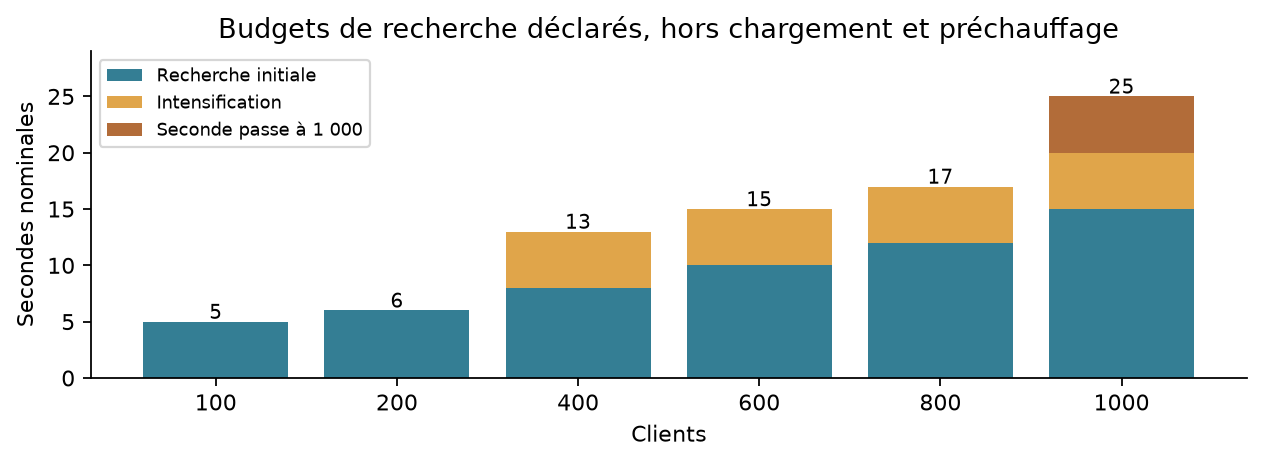

In [11]:
display(Image(filename=str(FIG/'budgets.png')))

Quatre processus mono-thread sont affectés à des cœurs distincts. Les temps
mesurent chaque recherche, construction incluse ; chargement et préchauffage
sont séparés. Les caches partagés, la température du processeur et le système
d'exploitation peuvent encore influencer ces mesures. Nous ne déduisons pas
une supériorité de vitesse face à un rapport exécuté séquentiellement ailleurs.
Dans les 80 nouvelles recherches, chaque processus effectue toutes les phases
de sa résolution. Dans l'extension, des continuations ont été exécutées sur
d'autres cœurs ; cette différence est enregistrée dans les protocoles.
Les états intermédiaires d'une trajectoire ne sont jamais comptés comme des
résolutions indépendantes supplémentaires.

Nous calculons, pour chaque solution réalisable :

$$g_r=100\left(\frac{D_r}{D_{\mathrm{BKS},r}}-1\right).$$

La BKS est une meilleure solution publiée, pas forcément un optimum prouvé.
Le nombre de véhicules peut différer de celui de la BKS si le maximum du fichier
est respecté : le critère DIMACS reste la distance. Toute solution irréalisable
est un échec ; elle ne reçoit pas un gap nul.

La moyenne des exécutions réalisables et la moyenne des moyennes par instance
pondèrent différemment les cas ayant un ou trois essais. Nous présentons
les deux agrégations et leurs effectifs. Aucun résultat n'est remplacé par le
meilleur de plusieurs recherches. Certains cas étaient déjà connus lors des
pilotes : cette campagne est une étude de couverture, pas un test entièrement
aveugle sur de nouvelles géographies.

## 5. Vérifications de correction

Le vérificateur ne réutilise pas les caches d'insertion. Il parcourt les
tournées, contrôle chaque identifiant, l'unicité, la couverture complète,
la flotte maximale, les charges, les fenêtres et le retour. Il recalcule le coût.
Les 356 références publiques sont également revérifiées et leurs coûts reproduits.

Les tests couvrent notamment l'ouverture d'un véhicule qui réduit la distance,
les clients absents ou répétés, surcharge, retard, attente, retour au dépôt,
protection de l'archive et accord entre noyau rapide et calcul indépendant.
Un test réussi ne démontre pas l'optimalité du solveur.

Le rapport de tests contient **15 tests réussis**, sans erreur ni échec.

## 6. Résultats de l'étude principale

Le premier bilan regroupe les 80 nouvelles exécutions. Le tableau par taille
en précise la répartition ; le détail des 24 instances à 100 clients suit ensuite.

| Indicateur | Résultat |
| --- | --- |
| Solutions réalisables | 80 /80 |
| Gap moyen par exécution (%) | 0,407 |
| Moyenne à poids égal par instance (%) | 0,392 |
| Médiane (%) | 0,000 |
| Écart-type (points) | 0,740 |
| Pire gap (%) | 3,379 |
| Essais sous 7 % | 80 /80 |

| État | Gap moy. (%) | Pire gap (%) | Temps cumulé moy. (s) |
| --- | --- | --- | --- |
| Recherche initiale | 0,533 | 6,908 | 5,776 |
| Profil final | 0,407 | 3,379 | 6,527 |

L'avant/après suit les mêmes 80 trajectoires du lot principal. L'amélioration comprend
l'effet du temps supplémentaire ; elle ne prouve pas à elle seule une
supériorité à budget total égal. Le pilote apparié décrit plus haut compare
les mécanismes sur six cas, avec une portée plus limitée.

| Clients | Essais | Valides | Sous 7 % | Gap moy. (%) | Pire gap (%) | Temps moy. (s) |
| --- | --- | --- | --- | --- | --- | --- |
| 100 | 72 | 72 | 72 | 0,316 | 1,884 | 5,000 |
| 200 | 2 | 2 | 2 | 0,109 | 0,219 | 6,001 |
| 1000 | 6 | 6 | 6 | 1,594 | 3,379 | 25,022 |

Une boîte à moustaches représente les quartiles Q1 et Q3 ; le trait central
est la médiane et le symbole supplémentaire la moyenne. Les moustaches vont
jusqu'aux valeurs observées situées à moins de $1{,}5(Q3-Q1)$ des quartiles.
Les points au-delà restent dans les statistiques : ce sont des valeurs éloignées,
pas automatiquement des erreurs. Le graphique par instance montre séparément
la moyenne et l'étendue minimum–maximum.

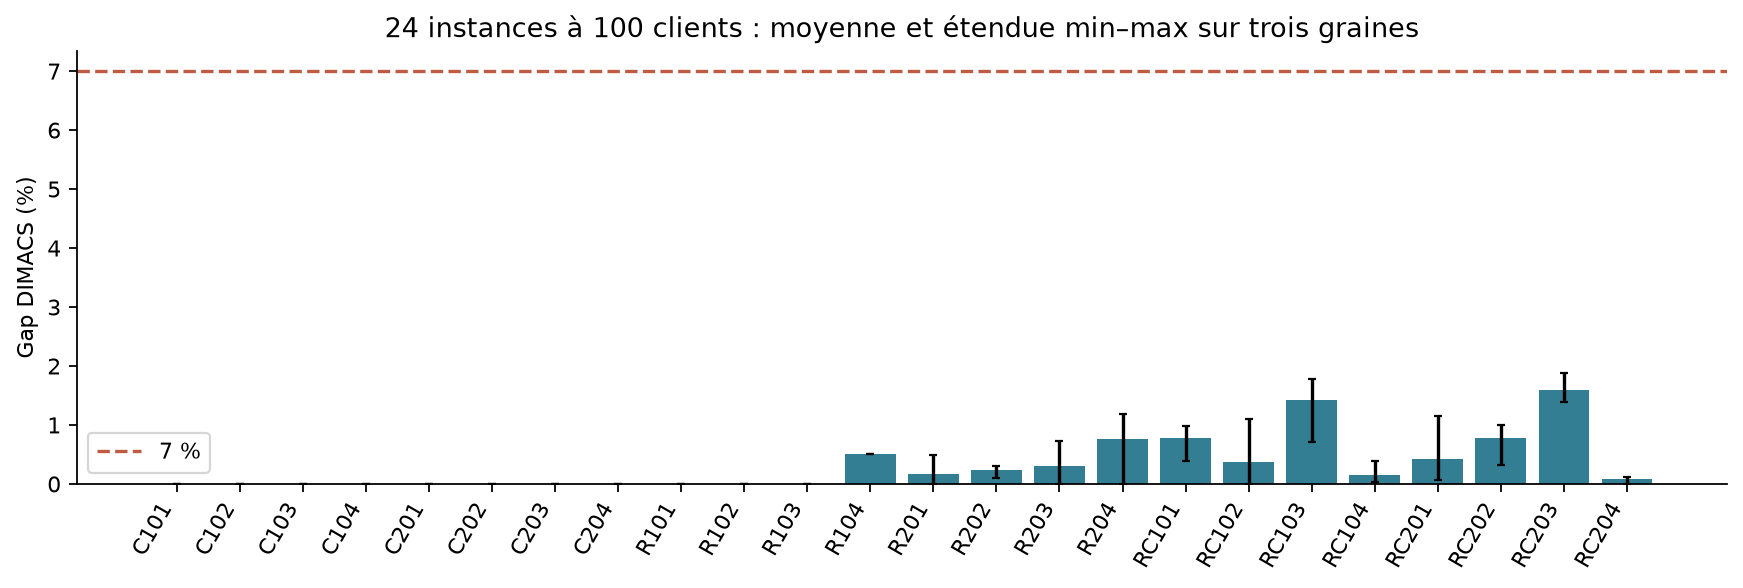

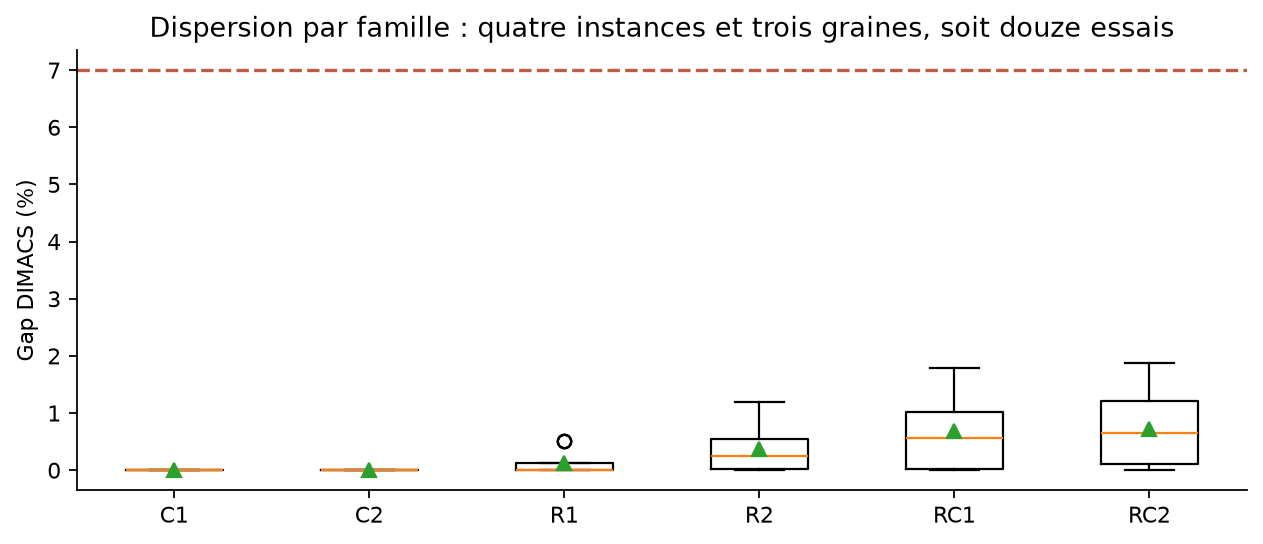

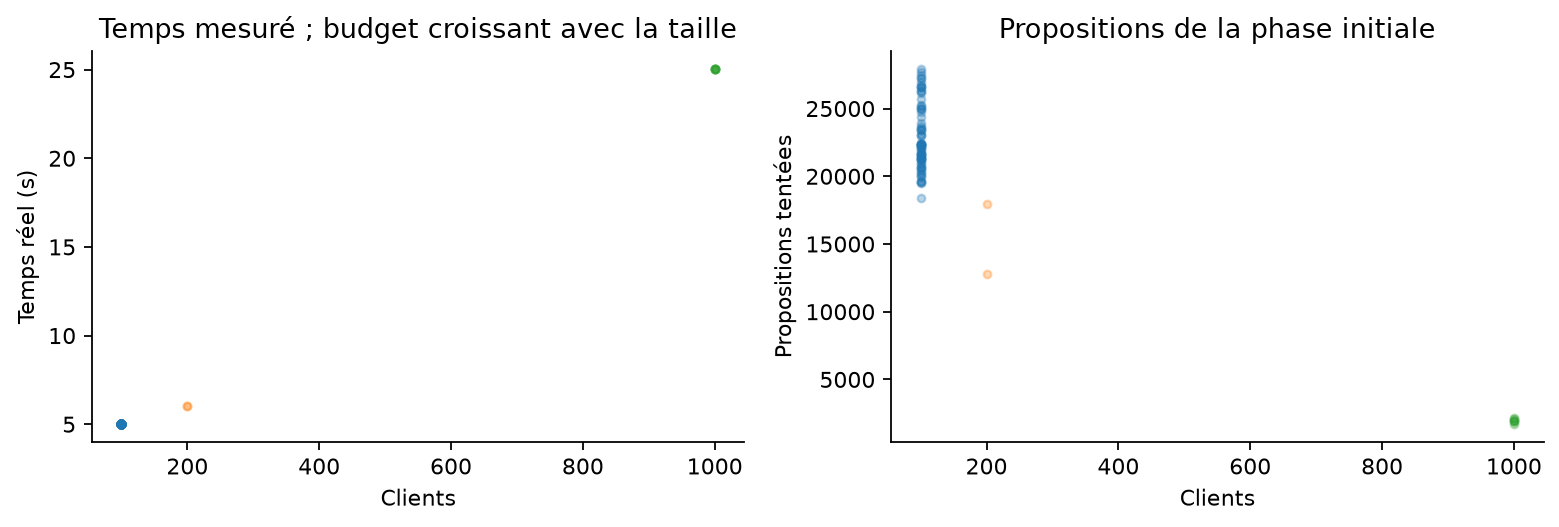

In [12]:
display(Image(filename=str(FIG/'gaps.png')))
display(Image(filename=str(FIG/'families.png')))
display(Image(filename=str(FIG/'scaling.png')))

Les 80 solutions réalisables du lot principal ont un gap moyen de 0.407 % et un pire gap de 3.379 %. 80 essais sur 80 sont strictement sous 7 %. Les barres à 100 clients indiquent la moyenne et le minimum–maximum des trois graines ; les boîtes comparent les douze exécutions de chaque famille. Les budgets différents selon la taille empêchent d’attribuer toute variation de temps à la seule taille.

### 6.1. Répétitions et cas difficiles

Les graines modifient les retraits, insertions bruitées et acceptations. Deux
exécutions du même problème peuvent donc aboutir à des affectations différentes.
La moyenne décrit le niveau observé ; le maximum révèle une fragilité que la
moyenne peut masquer. Deux ou trois répétitions restent peu pour estimer la
probabilité d'un échec rare.

| Instance | Référence | Meilleur coût | Gap moy. (%) | Pire gap (%) | Temps moy. (s) |
| --- | --- | --- | --- | --- | --- |
| C101 | 827,300 | 827,300 | 0,000 | 0,000 | 5,000 |
| C102 | 827,300 | 827,300 | 0,000 | 0,000 | 5,000 |
| C103 | 826,300 | 826,300 | 0,000 | 0,000 | 5,001 |
| C104 | 822,900 | 822,900 | 0,000 | 0,000 | 5,000 |
| C201 | 589,100 | 589,100 | 0,000 | 0,000 | 5,000 |
| C202 | 589,100 | 589,100 | 0,000 | 0,000 | 5,000 |
| C203 | 588,700 | 588,700 | 0,000 | 0,000 | 5,000 |
| C204 | 588,100 | 588,100 | 0,000 | 0,000 | 5,000 |
| R101 | 1637,700 | 1637,700 | 0,000 | 0,000 | 5,000 |
| R102 | 1466,600 | 1466,600 | 0,000 | 0,000 | 5,001 |
| R103 | 1208,700 | 1208,700 | 0,000 | 0,000 | 5,001 |
| R104 | 971,500 | 976,400 | 0,508 | 0,515 | 5,001 |
| R201 | 1143,200 | 1143,200 | 0,172 | 0,490 | 5,000 |
| R202 | 1029,600 | 1030,600 | 0,233 | 0,301 | 5,000 |
| R203 | 870,800 | 870,800 | 0,306 | 0,735 | 5,001 |
| R204 | 731,300 | 731,300 | 0,770 | 1,190 | 5,001 |
| RC101 | 1619,800 | 1626,100 | 0,784 | 0,982 | 5,001 |
| RC102 | 1457,400 | 1457,400 | 0,368 | 1,105 | 5,001 |
| RC103 | 1258,000 | 1267,000 | 1,420 | 1,781 | 5,000 |
| RC104 | 1132,300 | 1132,600 | 0,150 | 0,397 | 5,001 |
| RC201 | 1261,800 | 1262,600 | 0,425 | 1,149 | 5,000 |
| RC202 | 1092,300 | 1095,800 | 0,772 | 0,998 | 5,000 |
| RC203 | 923,700 | 936,500 | 1,595 | 1,884 | 5,000 |
| RC204 | 783,500 | 783,500 | 0,077 | 0,115 | 5,001 |

Ce tableau conserve les 24 instances à 100 clients du lot principal, avec
leurs trois graines. Il ne sélectionne pas seulement la meilleure exécution.

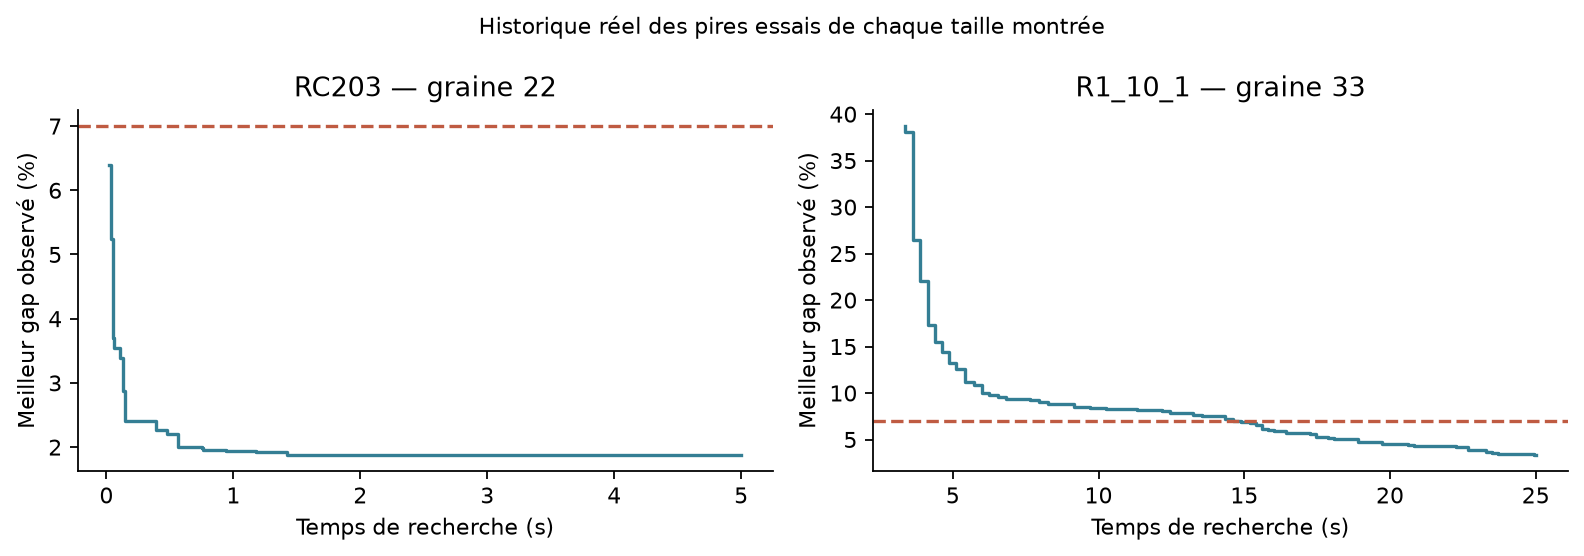

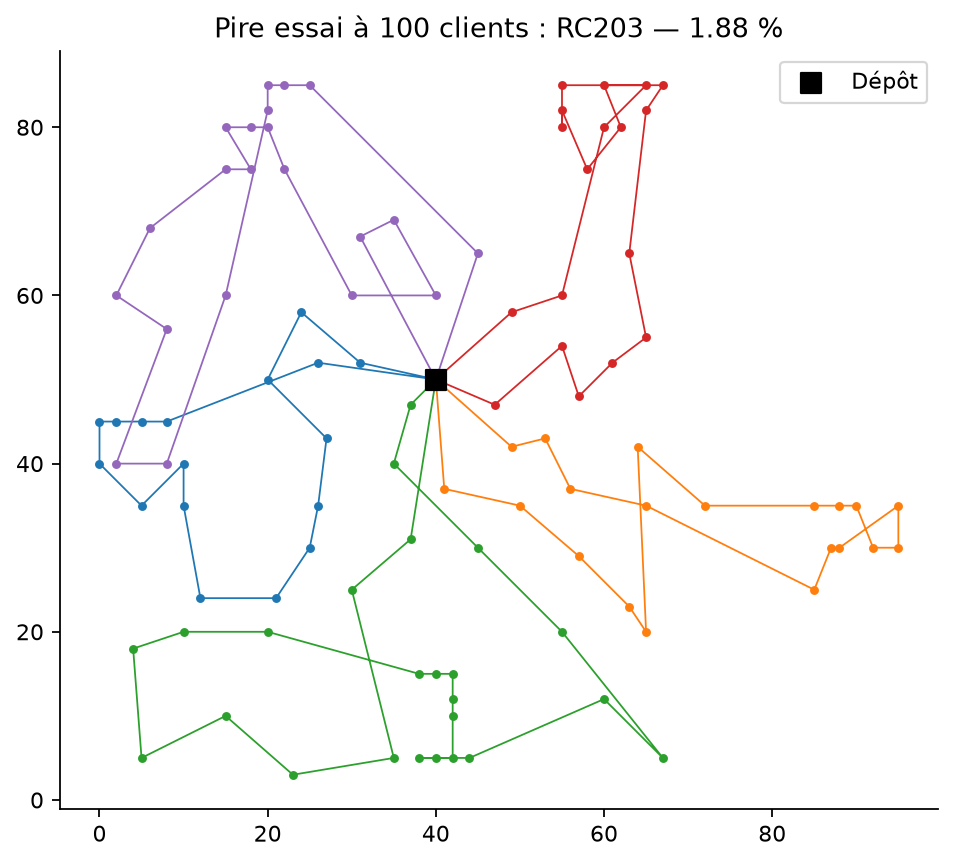

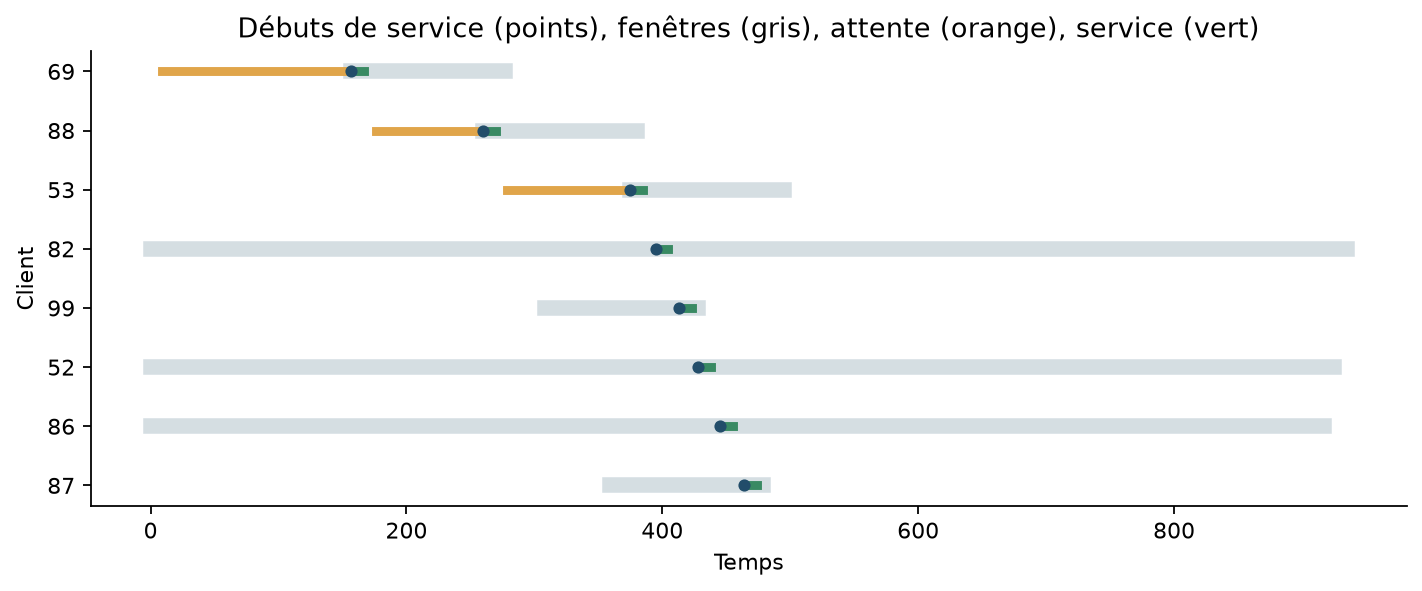

In [13]:
display(Image(filename=str(FIG/'convergence.png')))
display(Image(filename=str(FIG/'routes.png')))
display(Image(filename=str(FIG/'route_schedule.png')))

Le pire essai affiché à 100 clients est RC203, graine 22, à 1.884 %. Le pire essai affiché à 1000 clients est R1_10_1, graine 33, à 3.379 %. La carte représente le cas difficile à 100 clients ; les horaires sont contrôlés par le vérificateur, pas par le dessin.

### 6.2. Sensibilité aux choix algorithmiques

| Variante | Essais | Valides | Gap moy. (%) | Pire gap (%) |
| --- | --- | --- | --- | --- |
| Retraits limités à dix clients | 12 | 12 | 0,879 | 3,354 |
| Réglage initial | 12 | 12 | 0,052 | 0,379 |
| Sans adaptation | 12 | 12 | 0,071 | 0,747 |
| Sans recuit | 12 | 12 | 0,166 | 1,095 |
| Température initiale basse | 12 | 12 | 0,297 | 2,127 |
| Température initiale haute | 12 | 12 | 0,085 | 0,463 |

Ces expériences utilisent six cas et deux graines à deux secondes. Elles
éclairent le comportement local de paramètres ; elles ne prouvent pas un
classement universel des variantes. Le profil des mille résolutions reste figé.

## 7. Grandes instances et portée des résultats

| Instance | Clients | Essais | Gap moy. (%) | Pire gap (%) | Temps moy. (s) |
| --- | --- | --- | --- | --- | --- |
| C1_10_1 | 1000 | 3 | 0,002 | 0,006 | 25,025 |
| C1_2_1 | 200 | 1 | 0,000 | 0,000 | 6,001 |
| R1_10_1 | 1000 | 3 | 3,186 | 3,379 | 25,020 |
| R1_2_1 | 200 | 1 | 0,219 | 0,219 | 6,001 |

Ces quatre problèmes complètent l'étude à 100 clients. Les six recherches à
1 000 clients sont nouvelles et comprennent construction, ALNS et deux passes
d'intensification. Leurs budgets sont plus longs ; leur qualité et leurs temps
doivent donc être commentés ensemble.

L'extension suivante conserve les mille trajectoires sur les 356 problèmes.
Elle donne une vision plus large et comprend des cas moins favorables que
ceux du lot principal. Ses chiffres ne sont pas fusionnés avec les 80 nouveaux
essais et aucun échec n'est retiré.

| Clients | Essais | Valides | Sous 7 % | Gap moy. (%) | Pire gap (%) | Temps moy. (s) | Temps max. (s) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 100 | 160 | 160 | 160 | 0,426 | 3,168 | 5,001 | 5,008 |
| 200 | 170 | 170 | 170 | 1,120 | 5,806 | 6,001 | 6,011 |
| 400 | 166 | 166 | 160 | 2,434 | 9,293 | 13,005 | 13,009 |
| 600 | 171 | 171 | 139 | 4,025 | 15,262 | 15,009 | 15,032 |
| 800 | 166 | 166 | 130 | 4,990 | 11,985 | 17,012 | 17,046 |
| 1000 | 167 | 167 | 104 | 5,927 | 15,140 | 25,021 | 25,055 |

**Diagnostic séparé sur six cas difficiles de l'extension.** Le tableau suivant
compare deux continuations de cinq secondes depuis les mêmes solutions.
Ces lignes ne font pas partie des 80 nouveaux essais du lot principal.
Leur sélection après observation est déclarée ; tous les résultats du pilote
sont conservés, y compris celui où les groupes de tournées régressent.

| Instance | Continuation globale (%) | Groupes de tournées (%) |
| --- | --- | --- |
| C2_10_10 | 16,895 | 11,037 |
| C2_10_4 | 11,863 | 8,403 |
| C2_10_7 | 16,948 | 9,716 |
| R2_10_1 | 14,864 | 12,054 |
| R2_10_3 | 12,856 | 13,553 |
| RC2_10_9 | 13,252 | 11,960 |

Les 1 000 solutions de l'extension sont réalisables ; leur gap moyen est de
3,169 %, avec un maximum de 15,262 %. Sur les 167 essais à 1 000 clients,
la moyenne vaut 5,927 %, mais le maximum 15,140 %. Ces écarts montrent que
la réussite sur deux grandes instances ne garantit pas le seuil sur tout le jeu.

## 8. Retour à la durée des tournées

La distance ne représente pas toute la journée d'un véhicule. Pour six cas
supplémentaires, nous comparons deux continuations depuis les **mêmes tournées
initiales**, l'une visant la distance, l'autre la durée. Chaque continuation
dispose d'une seconde ; trois graines sont utilisées. Le temps ayant servi à
produire le départ est enregistré séparément. Aucun gap BKS en durée n'est annoncé.

| Instance | Durée mode distance | Durée mode durée | Attente mode durée | Trajet mode durée | Service | Variation durée (%) |
| --- | --- | --- | --- | --- | --- | --- |
| C105 | 9827,300 | 9827,300 | 0,000 | 827,300 | 9000,000 | 0,000 |
| C205 | 9586,400 | 9586,400 | 0,000 | 586,400 | 9000,000 | 0,000 |
| R105 | 2758,100 | 2706,400 | 202,633 | 1503,767 | 1000,000 | -1,874 |
| R205 | 3784,400 | 2671,567 | 37,333 | 1634,233 | 1000,000 | -29,406 |
| RC105 | 3152,000 | 2908,900 | 88,833 | 1820,067 | 1000,000 | -7,713 |
| RC205 | 5689,900 | 3344,533 | 48,100 | 2296,433 | 1000,000 | -41,220 |

L'attente explique qu'une affectation plus courte géographiquement puisse
rester longue en durée. Les services sont imposés par les données : leur somme
ne diminue pas en réordonnant les clients.

## 9. Reproduction et limites

Les données, références, paramètres et empreintes sont enregistrés. Chaque
exécution possède son fichier JSON avec ses tournées, sa graine, son historique,
son coût et ses temps. Les tableaux complets conservent les 356 instances.
Le Notebook reconstruit les analyses et exécute un petit contrôle ; il ne
relance pas les mille recherches à chaque ouverture.

In [14]:
runs=pd.read_csv(ROOT/'results/report/etude_principale_80.csv')
assert len(runs)==80
display(runs[['instance','n','seed','status','distance','reference_distance','gap_pct','runtime_s']].head(12))
print('Extrait : 12 lignes sur 80. Les CSV et les tableaux HTML conservent les lots complets séparément.')

,instance,n,seed,status,distance,reference_distance,gap_pct,runtime_s
0,C101,100,11,feasible,827.3,827.3,0.0,5.000461
1,C101,100,22,feasible,827.3,827.3,0.0,5.000424
2,C101,100,33,feasible,827.3,827.3,0.0,5.000553
3,C102,100,11,feasible,827.3,827.3,0.0,5.000453
4,C102,100,22,feasible,827.3,827.3,0.0,5.000389
5,C102,100,33,feasible,827.3,827.3,0.0,5.000369
6,C103,100,11,feasible,826.3,826.3,0.0,5.000733
7,C103,100,22,feasible,826.3,826.3,0.0,5.000515
8,C103,100,33,feasible,826.3,826.3,0.0,5.000505
9,C104,100,11,feasible,822.9,822.9,0.0,5.000363


Extrait : 12 lignes sur 80. Les CSV et les tableaux HTML conservent les lots complets séparément.


Le [tableau HTML des 80 nouveaux essais](../livraison/ETUDE_80_EXECUTIONS.html)
conserve tout le lot principal. Le [tableau des mille exécutions de l'extension](../livraison/MILLE_EXECUTIONS.html)
permet de filtrer les lignes. Le CSV `results/report/mille_executions.csv`
conserve les valeurs numériques complètes pour une analyse complémentaire.

```powershell
..\.venv\Scripts\python.exe scripts\run_campaign.py
..\.venv\Scripts\python.exe scripts\run_polish_campaign.py
..\.venv\Scripts\python.exe scripts\run_largest_polish.py
..\.venv\Scripts\python.exe -m pytest tests
..\.venv\Scripts\python.exe scripts\build_report.py
```

La convention tronquée, le trafic statique, le nombre réduit de graines par
problème et les budgets limités bornent la portée de l'étude. Un bon gap moyen
ne garantit pas un seuil inférieur à 7 % sur chaque exécution. Les résultats
sans solution et les cas dépassant ce seuil restent dans le bilan.

## 10. Conclusion

Le lot principal fournit 80 solutions réalisables sur 80, avec un gap moyen de 0.407 % et un maximum de 3.379 %. L’extension à 356 instances et mille trajectoires reste présentée séparément : elle révèle des difficultés supplémentaires et empêche de généraliser les résultats du lot principal à tout le jeu.

Le travail associe une représentation vérifiable, une méthode d'amélioration
et des mesures traçables. Les suites les plus utiles sont une réparation plus
profonde sur les grands cas difficiles, davantage de répétitions sur ces cas
et une évaluation à budget identique des variantes les plus prometteuses.
L'extension au trafic dépendant de l'heure demanderait un autre modèle de temps
et d'autres références ; les gaps présentés ici ne la valident pas.

## Références

- CESI, *Algorithmique et optimisation*, sujet et attentes du livrable final.
- Ropke et Pisinger, *An Adaptive Large Neighborhood Search Heuristic for the
  Pickup and Delivery Problem with Time Windows*, 2006,
  [publication](https://doi.org/10.1287/trsc.1050.0135).
- Kirkpatrick, Gelatt et Vecchi, *Optimization by Simulated Annealing*, 1983,
  [publication](https://doi.org/10.1126/science.220.4598.671).
- [PyVRP/Instances : convention VRPTW et DIMACS](https://github.com/PyVRP/Instances/blob/main/VRPTW/README.md).
- [VRPLIB : lecture des instances et solutions](https://github.com/PyVRP/VRPLIB).
- [Numba : compilation des fonctions numériques](https://numba.readthedocs.io/en/stable/user/jit.html).

### Contrôle exécutable court

Ce contrôle de fonctionnement est distinct des mille recherches de la campagne.

In [15]:
startup=warmup()
instance=load(ROOT/'data/instances/C101.vrp')
demo=solve(instance,Settings(seconds=.2,seed=9999))
assert demo['status']=='feasible' and verify(demo['routes'],instance)['valid']
print('Contrôle réalisable ; distance :',demo['cost'],'; véhicules :',demo['vehicles'])

Contrôle réalisable ; distance : 827.3 ; véhicules : 10
